# **Cleaning DSSP and ConSurf**

In [2]:
import pandas as pd
import numpy as np

def parse_hbond(field):
    if not field or ',' not in field:
        return (None, None)
    parts = field.split(',')
    try:
        partner = int(parts[0])
        energy = float(parts[1])
        return (partner, energy)
    except ValueError:
        return (None, None)


def parse_dssp(file_path):
    data = []
    header_found = False

    with open(file_path, "r") as f:
        for line in f:
            line = line.rstrip("\n")

            if line.startswith("  #  RESIDUE"):
                header_found = True
                continue

            if not header_found:
                continue


            if not line.strip():
                continue

            try:
                res_seq = int(line[5:10].strip())
                chain_id = line[11].strip()
                aa = line[13].strip()
                ss = line[16].strip()
                acc = int(line[34:38].strip()) if line[34:38].strip() else None

                # Hydrogen bonds
                nh_o_1_partner, nh_o_1_energy = parse_hbond(line[39:50].strip())
                o_hn_1_partner, o_hn_1_energy = parse_hbond(line[50:61].strip())
                nh_o_2_partner, nh_o_2_energy = parse_hbond(line[61:72].strip())
                o_hn_2_partner, o_hn_2_energy = parse_hbond(line[72:83].strip())

                phi = float(line[103:109].strip()) if line[103:109].strip() else None
                psi = float(line[109:115].strip()) if line[109:115].strip() else None
                x = float(line[115:122].strip()) if line[115:122].strip() else None
                y = float(line[122:129].strip()) if line[122:129].strip() else None
                z = float(line[129:136].strip()) if line[129:136].strip() else None

                data.append({
                    "res_seq": res_seq,
                    "chain": chain_id,
                    "aa": aa,
                    "ss": ss,
                    "acc": acc,
                    "nh_o_1_partner": nh_o_1_partner,
                    "nh_o_1_energy": nh_o_1_energy,
                    "o_hn_1_partner": o_hn_1_partner,
                    "o_hn_1_energy": o_hn_1_energy,
                    "nh_o_2_partner": nh_o_2_partner,
                    "nh_o_2_energy": nh_o_2_energy,
                    "o_hn_2_partner": o_hn_2_partner,
                    "o_hn_2_energy": o_hn_2_energy,
                    "phi": phi,
                    "psi": psi,
                    "x": x,
                    "y": y,
                    "z": z
                })
            except Exception:
                continue

    df = pd.DataFrame(data)

    if set(["x", "y", "z"]).issubset(df.columns):
        mask = df[["x", "y", "z"]].notna().all(axis=1)
        df["ca_contact_8A"] = np.nan
        if mask.any():
            coords = df.loc[mask, ["x", "y", "z"]].to_numpy()
            N = coords.shape[0]
            R2 = 8.0 ** 2
            contact_counts = np.zeros(N, dtype=int)
            block = 1024
            for i0 in range(0, N, block):
                i1 = min(i0 + block, N)
                a = coords[i0:i1]
                d2 = ((a[:, None, :] - coords[None, :, :]) ** 2).sum(axis=2)
                contact_counts[i0:i1] = (d2 <= R2).sum(axis=1) - 1
            df.loc[mask, "ca_contact_8A"] = contact_counts

    hb_cols = [c for c in ["nh_o_1_energy","o_hn_1_energy","nh_o_2_energy","o_hn_2_energy"] if c in df.columns]
    if hb_cols:
        df["hb_min_energy"] = df[hb_cols].min(axis=1, skipna=True)

    max_asa = {
        'A':121,'R':265,'N':187,'D':187,'C':148,'E':214,'Q':214,'G':97,'H':216,
        'I':195,'L':191,'K':230,'M':203,'F':228,'P':154,'S':143,'T':163,'W':264,
        'Y':255,'V':165
    }
    df["rsa_frac"] = np.where(
        df["aa"].isin(max_asa) & df["acc"].notna(),
        df["acc"] / df["aa"].map(max_asa),
        np.nan
    )

    return df

if __name__ == "__main__":
    file_path = "pkhd1.dssp"
    df = parse_dssp(file_path)

    output_file = "pkhd1_residues.csv"
    df.to_csv(output_file, index=False)
    print(f"Data exported to {output_file}")

Data exported to pkhd1_residues.csv


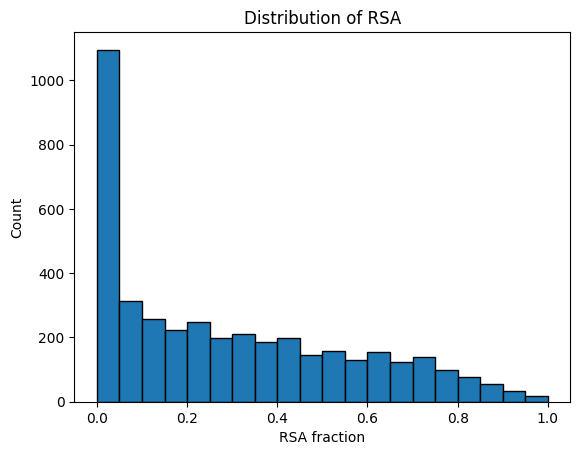

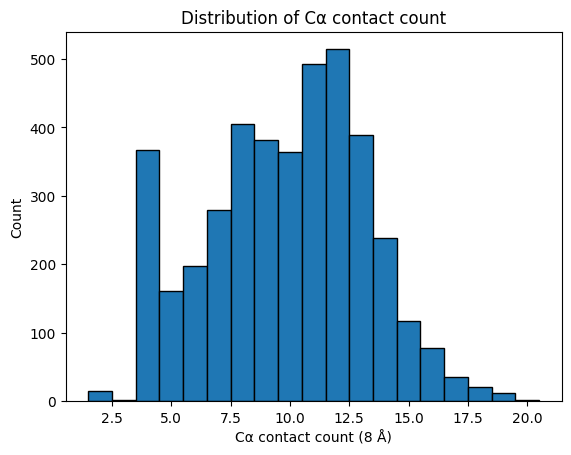

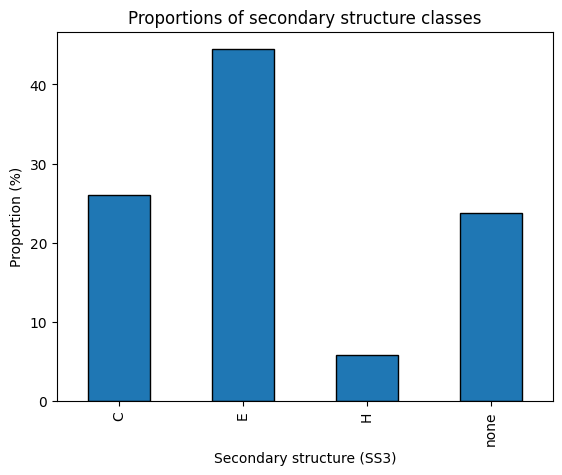

In [3]:
import matplotlib.pyplot as plt


plt.figure()
rsa_vals = df["rsa_frac"].dropna()
plt.hist(rsa_vals, bins=np.linspace(0, 1, 21), edgecolor="black")
plt.xlabel("RSA fraction")
plt.ylabel("Count")
plt.title("Distribution of RSA")
plt.show()

plt.figure()
values = df["ca_contact_8A"].dropna().astype(int)
plt.hist(values, bins=np.arange(values.min(), values.max()+2)-0.5, edgecolor="black")
plt.xlabel("Cα contact count (8 Å)")
plt.ylabel("Count")
plt.title("Distribution of Cα contact count")
plt.show()

plt.figure()
ss3 = df["ss"].fillna("none").map(
    lambda x: "H" if x in ["H","G","I"] else ("E" if x in ["E","B"] else ("C" if x.strip() else "none"))
)
proportions = (ss3.value_counts(normalize=True) * 100).sort_index()
proportions.plot(kind="bar", edgecolor="black")
plt.xlabel("Secondary structure (SS3)")
plt.ylabel("Proportion (%)")
plt.title("Proportions of secondary structure classes")
plt.show()

In [4]:
import pandas as pd
input_file = "pkhd1_consurf_grades.txt"

with open(input_file) as f:
    lines = f.readlines()
start_idx = None
for i, line in enumerate(lines):
    if line.strip().startswith("POS"):
        start_idx = i
        break

print(f"Table header found at line {start_idx}: {lines[start_idx]}")

consurf_df = pd.read_fwf(input_file, skiprows=start_idx)
if "ATOM" in consurf_df.columns:
    consurf_df["residue"] = consurf_df["ATOM"].astype(str).str.strip()
else:
    raise ValueError("No ATOM column found in ConSurf file")

consurf_df["consurf_grade_clean"] = (
    consurf_df["COLOR"]
    .astype(str)
    .str.extract(r"(\d+)")
)

consurf_df["consurf_grade_clean"] = pd.to_numeric(consurf_df["consurf_grade_clean"], errors="coerce")
out = consurf_df[["residue", "consurf_grade_clean"]].dropna().reset_index(drop=True)

# Save
out.to_csv("pkhd1_residue_grades.csv", index=False)
print("Saved: pkhd1_residue_grades.csv")
print(out.head(10))

Table header found at line 27:  POS	SEQ	      ATOM	 SCORE	COLOR	CONFIDENCE INTERVAL	B/E	F/S	MSA DATA	RESIDUE VARIETY

Saved: pkhd1_residue_grades.csv
    residue  consurf_grade_clean
0   MET:1:A                  9.0
1   THR:2:A                  4.0
2   ALA:3:A                  2.0
3   TRP:4:A                  3.0
4   LEU:5:A                  5.0
5   ILE:6:A                  3.0
6   SER:7:A                  4.0
7   LEU:8:A                  4.0
8   MET:9:A                  3.0
9  SER:10:A                  5.0


# **Naive Bayes**

In [5]:
import numpy as np, pandas as pd, json, re

PRIOR_PI = 0.099  # ClinVar: ~10% pathogenic
WEIGHTS = {"rsa": 1.2, "contacts": 0.8, "hbmin": 0.6}
LRS_SS = {"E": 1.8, "H": 1.2, "C": 1.0, "NA": 1.0}
EPS = 1e-4
LOG_LR_CLIP = (-6.9, 6.9)
AMINO_ACIDS = list("ACDEFGHIKLMNPQRSTVWY")

LRS_CONSURF = {
    1: 0.7, 2: 0.8, 3: 0.9,
    4: 1.0, 5: 1.0, 6: 1.0,
    7: 1.5, 8: 2.0, 9: 2.5
}

INDICATOR_COLS = [
    'buried_pro',
    'buried_hydrophilic',
    'buried_charge_intro',
    'buried_charge_switch',
    'buried_charge_replaced',
    'buried_gly_replaced',
    'cis_pro_replaced'
]

def ecdf_percentile(sorted_vals, x):
    if sorted_vals is None or len(sorted_vals) == 0 or pd.isna(x):
        return np.nan
    k = np.searchsorted(sorted_vals, x, side='right')
    return k / len(sorted_vals)

def log_lr_from_tail(t, weight):
    if pd.isna(t): return 0.0
    t = max(float(t), EPS)
    val = weight * np.log(0.5 / t)
    return float(np.clip(val, *LOG_LR_CLIP))

def logit(p):
    p = min(max(float(p), 1e-6), 1-1e-6)
    return np.log(p/(1-p))

def inv_logit(z):
    return 1.0/(1.0+np.exp(-z))

class BayesScorer:
    def __init__(self, rsa_wt, cnt_wt, hb_wt,
                 weights=WEIGHTS, ss_lrs=LRS_SS,
                 consurf_lrs=LRS_CONSURF, prior=PRIOR_PI):
        self.rsa_wt = rsa_wt
        self.cnt_wt = cnt_wt
        self.hb_wt  = hb_wt
        self.weights = dict(weights)
        self.ss_lrs = dict(ss_lrs)
        self.consurf_lrs = dict(consurf_lrs)
        self.prior   = float(prior)

    def _map_ss8_to_ss3(self, s):
        if pd.isna(s): return 'C'
        c = str(s).strip()
        if c in ('H','G','I'): return 'H'
        if c in ('E','B'):     return 'E'
        return 'C'

    def _logLR_ss(self, s):
        ss3 = self._map_ss8_to_ss3(s)
        return float(np.log(self.ss_lrs.get(ss3, 1.0)))

    def _logLR_consurf(self, g):
        if pd.isna(g): return 0.0
        g = int(g)
        return float(np.log(self.consurf_lrs.get(g, 1.0)))

    def score_positions(self, df):
        out = df.copy()

        u_rsa = out['rsa_frac'].apply(lambda x: ecdf_percentile(self.rsa_wt, x))
        u_cnt = out['ca_contact_8A'].apply(lambda x: ecdf_percentile(self.cnt_wt, x))
        u_hb  = out['hb_min_energy'].apply(lambda x: ecdf_percentile(self.hb_wt, x))

        t_rsa = u_rsa
        t_cnt = 1 - u_cnt if len(self.cnt_wt) else pd.Series(np.nan, index=out.index)
        t_hb  = u_hb

        logLR_rsa = t_rsa.map(lambda t: log_lr_from_tail(t, self.weights['rsa']))
        logLR_cnt = t_cnt.map(lambda t: log_lr_from_tail(t, self.weights['contacts']))
        logLR_hb  = t_hb.map(lambda t: log_lr_from_tail(t, self.weights['hbmin']))
        logLR_ss  = out['ss'].map(self._logLR_ss)
        logLR_consurf = out['consurf_grade_clean'].map(self._logLR_consurf)

        for col in INDICATOR_COLS:
            if col not in out.columns:
                out[col] = False
        logLR_subs = sum(out[c].astype(float) for c in INDICATOR_COLS)

        total_log_odds = (logit(self.prior) +
                          logLR_rsa + logLR_cnt + logLR_hb +
                          logLR_ss + logLR_consurf + logLR_subs)
        posterior = inv_logit(total_log_odds)

        out['posterior_pathogenic'] = posterior
        return out

def generate_all_subs(df):
    rows = []
    for _, row in df.iterrows():
        wt = row['aa']
        pos = row['res_seq']
        for alt in AMINO_ACIDS:
            if alt != wt:
                r = row.copy()
                r['ref_aa'] = wt
                r['alt_aa'] = alt
                r['protein_variant'] = f"p.{wt}{pos}{alt}"
                rows.append(r)
    return pd.DataFrame(rows)

def add_indicators(df):
    out = df.copy()
    hydrophobic = set("AILMFWV")
    hydrophilic = set("STNQYC")
    charged = set("DEKRH")
    acidic = set("DE"); basic = set("KRH")

    out['buried_pro'] = (out['alt_aa'] == 'P') & (out['rsa_frac'] < 0.2)
    out['buried_hydrophilic'] = out['ref_aa'].isin(hydrophobic) & out['alt_aa'].isin(hydrophilic) & (out['rsa_frac'] < 0.2)
    out['buried_charge_intro'] = ~(out['ref_aa'].isin(charged)) & out['alt_aa'].isin(charged) & (out['rsa_frac'] < 0.2)
    out['buried_charge_switch'] = ((out['ref_aa'].isin(acidic) & out['alt_aa'].isin(basic)) |
                                   (out['ref_aa'].isin(basic) & out['alt_aa'].isin(acidic))) & (out['rsa_frac'] < 0.2)
    out['buried_charge_replaced'] = out['ref_aa'].isin(charged) & ~(out['alt_aa'].isin(charged)) & (out['rsa_frac'] < 0.2)
    out['buried_gly_replaced'] = (out['ref_aa'] == 'G') & (out['rsa_frac'] < 0.2) & (out['alt_aa'] != 'G')
    out['cis_pro_replaced'] = (out['ref_aa'] == 'P') & (out['alt_aa'] != 'P')

    return out

df = pd.read_csv("/content/pkhd1_residues.csv")
consurf = pd.read_csv("pkhd1_residue_grades.csv")

def parse_residue_number(s):
    if pd.isna(s):
        return None
    m = re.search(r":(\d+):", str(s))
    return int(m.group(1)) if m else None

consurf["res_seq"] = consurf["residue"].apply(parse_residue_number)
df["res_seq"] = pd.to_numeric(df["res_seq"], errors="coerce").astype(int)

df = df.merge(
    consurf[["res_seq", "consurf_grade_clean"]],
    on="res_seq", how="left"
)

df = df.drop_duplicates(subset=["res_seq", "aa"]).copy()

RSA_WT = np.sort(df['rsa_frac'].dropna().to_numpy())
CNT_WT = np.sort(df['ca_contact_8A'].dropna().to_numpy())
HB_WT  = np.sort(df['hb_min_energy'].dropna().to_numpy())

df_subs = generate_all_subs(df)
df_subs = add_indicators(df_subs)

scorer = BayesScorer(RSA_WT, CNT_WT, HB_WT)
scored_subs = scorer.score_positions(df_subs)

scored_subs.to_csv("all_substitutions_posteriors.csv", index=False)

meta = dict(
    prior_pi=PRIOR_PI,
    weights=WEIGHTS,
    LRs=dict(SS=LRS_SS, ConSurf=LRS_CONSURF),
    tails={"rsa":"left","contacts":"right","hbmin":"left"},
    eps=EPS, logLR_clip=LOG_LR_CLIP,
    WT_sizes={"rsa": len(RSA_WT), "contacts": len(CNT_WT), "hbmin": len(HB_WT)},
    indicators=INDICATOR_COLS
)
with open("bayes_scorer_meta.json","w") as f:
    json.dump(meta, f, indent=2)

print("Saved: all_substitutions_posteriors.csv, bayes_scorer_meta.json")
print(f"Total unique residues: {df.shape[0]}")
print(f"Total variants generated: {scored_subs.shape[0]} (should equal {df.shape[0]*19})")

Saved: all_substitutions_posteriors.csv, bayes_scorer_meta.json
Total unique residues: 4074
Total variants generated: 77406 (should equal 77406)


In [11]:
import pandas as pd

df = pd.read_csv("/content/all_substitutions_posteriors.csv")
posterior_col = "posterior_pathogenic"

def classify(p):
    if pd.isna(p):
        return "NA"
    elif p <= 0.35:
        return "Benign"
    elif p >= 0.55:
        return "Pathogenic"
    else:
        return "Uncertain"

df["classification"] = df[posterior_col].apply(classify)
df.to_csv("/content/ScalePKD.csv", index=False)

# **Plotting**

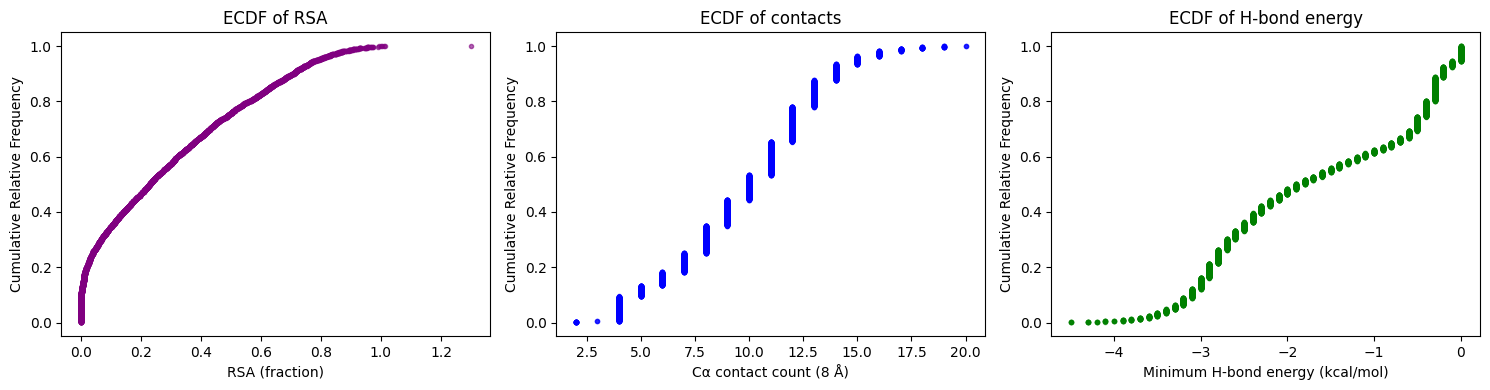

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd  # make sure pandas is imported

def plot_ecdf(data, xlabel, title, color):
    data = pd.Series(data).dropna().to_numpy()
    data.sort()
    y = np.arange(1, len(data)+1) / len(data)
    plt.plot(data, y, marker=".", linestyle="none", color=color, alpha=0.6)
    plt.xlabel(xlabel)
    plt.ylabel("Cumulative Relative Frequency")
    plt.title(title)

plt.figure(figsize=(15,4))

# RSA
plt.subplot(1,3,1)
plot_ecdf(RSA_WT, "RSA (fraction)", "ECDF of RSA", "purple")

# Contacts
plt.subplot(1,3,2)
plot_ecdf(CNT_WT, "Cα contact count (8 Å)", "ECDF of contacts", "blue")

# H-bonds
plt.subplot(1,3,3)
plot_ecdf(HB_WT, "Minimum H-bond energy (kcal/mol)", "ECDF of H-bond energy", "green")

plt.tight_layout()
plt.show()

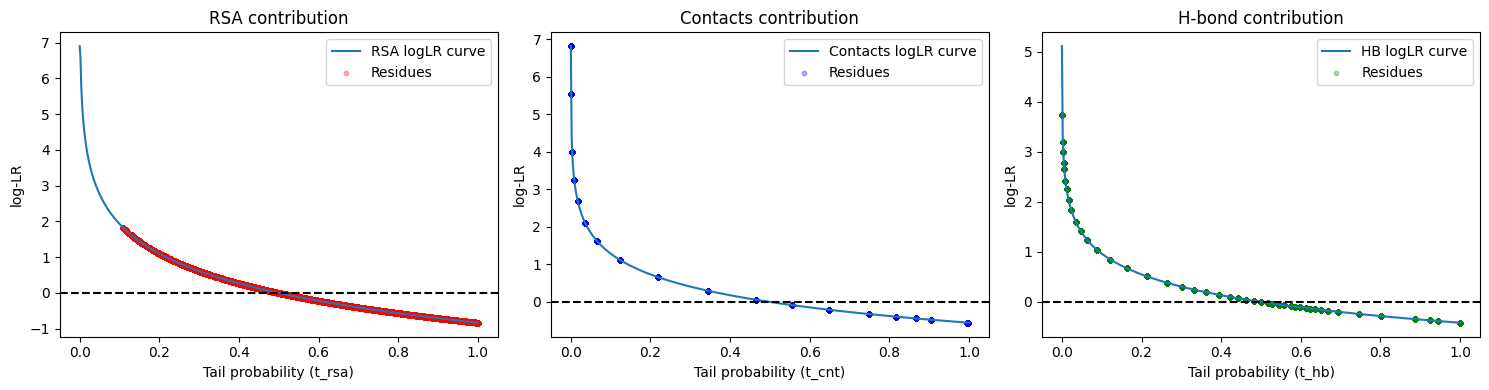

In [13]:
scored = scorer.score_positions(df)

df_tails = scored.copy()
df_tails['t_rsa'] = df_tails['rsa_frac'].apply(lambda x: ecdf_percentile(RSA_WT, x))
df_tails['t_cnt'] = df_tails['ca_contact_8A'].apply(lambda x: 1 - ecdf_percentile(CNT_WT, x) if pd.notna(x) else np.nan)
df_tails['t_hb']  = df_tails['hb_min_energy'].apply(lambda x: ecdf_percentile(HB_WT, x))


t_vals = np.linspace(1e-4, 1, 500)

plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.plot(t_vals, [log_lr_from_tail(t, WEIGHTS['rsa']) for t in t_vals], label="RSA logLR curve")
plt.scatter(df_tails['t_rsa'],
            [log_lr_from_tail(t, WEIGHTS['rsa']) for t in df_tails['t_rsa']],
            alpha=0.3, s=10, c="red", label="Residues")
plt.axhline(0, color="k", linestyle="--")
plt.xlabel("Tail probability (t_rsa)")
plt.ylabel("log-LR")
plt.title("RSA contribution")
plt.legend()

plt.subplot(1,3,2)
plt.plot(t_vals, [log_lr_from_tail(t, WEIGHTS['contacts']) for t in t_vals], label="Contacts logLR curve")
plt.scatter(df_tails['t_cnt'],
            [log_lr_from_tail(t, WEIGHTS['contacts']) for t in df_tails['t_cnt']],
            alpha=0.3, s=10, c="blue", label="Residues")
plt.axhline(0, color="k", linestyle="--")
plt.xlabel("Tail probability (t_cnt)")
plt.ylabel("log-LR")
plt.title("Contacts contribution")
plt.legend()

plt.subplot(1,3,3)
plt.plot(t_vals, [log_lr_from_tail(t, WEIGHTS['hbmin']) for t in t_vals], label="HB logLR curve")
plt.scatter(df_tails['t_hb'],
            [log_lr_from_tail(t, WEIGHTS['hbmin']) for t in df_tails['t_hb']],
            alpha=0.3, s=10, c="green", label="Residues")
plt.axhline(0, color="k", linestyle="--")
plt.xlabel("Tail probability (t_hb)")
plt.ylabel("log-LR")
plt.title("H-bond contribution")
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
# --------------------------
# Export data for GraphPad
# --------------------------
curve_df = pd.DataFrame({
    "t_vals": t_vals,
    "rsa_logLR_curve": [log_lr_from_tail(t, WEIGHTS['rsa']) for t in t_vals],
    "contacts_logLR_curve": [log_lr_from_tail(t, WEIGHTS['contacts']) for t in t_vals],
    "hb_logLR_curve": [log_lr_from_tail(t, WEIGHTS['hbmin']) for t in t_vals],
})

scatter_df = pd.DataFrame({
    "t_rsa_residues": df_tails['t_rsa'],
    "rsa_logLR_residues": df_tails['t_rsa'].map(lambda t: log_lr_from_tail(t, WEIGHTS['rsa'])),
    "t_cnt_residues": df_tails['t_cnt'],
    "contacts_logLR_residues": df_tails['t_cnt'].map(lambda t: log_lr_from_tail(t, WEIGHTS['contacts'])),
    "t_hb_residues": df_tails['t_hb'],
    "hb_logLR_residues": df_tails['t_hb'].map(lambda t: log_lr_from_tail(t, WEIGHTS['hbmin'])),
})

# Merge curve and scatter into one file with separate columns
export_df = pd.concat([curve_df, scatter_df], axis=1)

# Save to CSV
export_df.to_csv("logLR_curves_and_residues.csv", index=False)

print("Saved: logLR_curves_and_residues.csv")

Saved: logLR_curves_and_residues.csv


Total substitutions evaluated: 77406
                        count    percent
buried_charge_intro      8530  11.019818
buried_hydrophilic       5916   7.642818
cis_pro_replaced         4085   5.277369
buried_gly_replaced      3154   4.074620
buried_charge_replaced   2745   3.546237
buried_pro               1816   2.346071
buried_charge_switch      450   0.581350


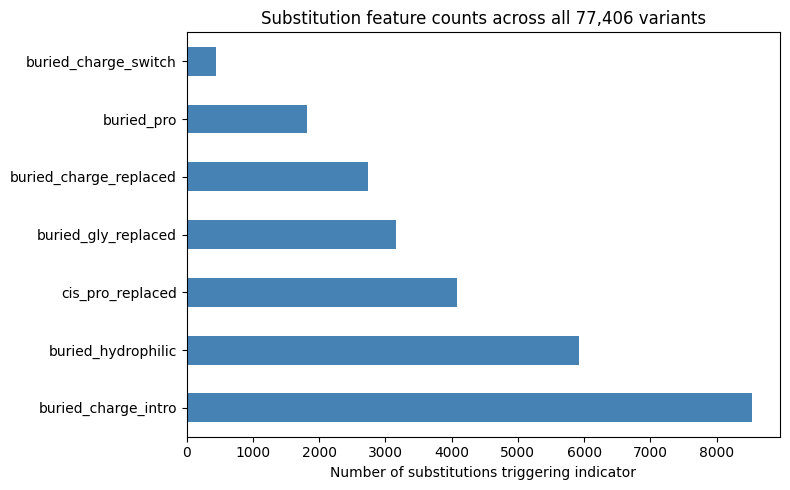

In [15]:
# --------------------------
# Quantify substitution indicators
# --------------------------

# Total number of possible substitutions
total_variants = len(df_subs)
print(f"Total substitutions evaluated: {total_variants}")

# Count how many substitutions trigger each indicator
indicator_counts = df_subs[INDICATOR_COLS].sum().sort_values(ascending=False)

# Convert to dataframe with counts and percentages
indicator_summary = pd.DataFrame({
    "count": indicator_counts,
    "percent": 100 * indicator_counts / total_variants
}).sort_values("count", ascending=False)

print(indicator_summary)

# Plot counts
import matplotlib.pyplot as plt
indicator_summary["count"].plot(kind="barh", figsize=(8,5), color="steelblue")
plt.xlabel("Number of substitutions triggering indicator")
plt.title(f"Substitution feature counts across all {total_variants:,} variants")
plt.tight_layout()
plt.show()

# **Variant Interpretation**

In [20]:
import pandas as pd

DOMAINS = [
    (24, 111, "IPT/TIG 1; atypical"),
    (137, 232, "IPT/TIG 2"),
    (259, 335, "IPT/TIG 3"),
    (322, 485, "PA14"),
    (547, 722, "Cysteine-rich domain 1"),
    (931, 1015, "IPT/TIG 4"),
    (1019, 1103, "IPT/TIG 5"),
    (1108, 1192, "IPT/TIG 6; atypical"),
    (1196, 1289, "IPT/TIG 7"),
    (1301, 1382, "IPT/TIG 8; atypical"),
    (1389, 1481, "IPT/TIG 9"),
    (1486, 1570, "IPT/TIG 10"),
    (1573, 1659, "IPT/TIG 11"),
    (1658, 1742, "IPT/TIG 12; atypical"),
    (1743, 1931, "Cysteine-rich domain 2"),
    (1932, 2053, "G8 1"),
    (2226, 2248, "PbH1 1"),
    (2249, 2271, "PbH1 2"),
    (2292, 2325, "PbH1 3"),
    (2326, 2347, "PbH1 4"),
    (2409, 2431, "PbH1 5"),
    (2469, 2502, "PbH1 6"),
    (2503, 2716, "FN3-like domain"),
    (2747, 2873, "G8 2"),
    (2874, 3556, "RβH-like domain"),
    (3010, 3032, "PbH1 7"),
    (3033, 3055, "PbH1 8"),
    (3086, 3108, "PbH1 9"),
    (3876, 3893, "Ciliary targeting sequence (CTS)"),
    (3952, 3976, "Nuclear localization signal (NLS)"),
]

def get_domain(res_num):
    """Return the domain annotation for a residue number, if any."""
    for start, end, name in DOMAINS:
        if start <= res_num <= end:
            return name
    return "outside annotated domains"

SS_MAP = {
    "H": "alpha helix",
    "G": "3-10 helix",
    "I": "pi helix",
    "E": "beta strand",
    "B": "beta bridge",
    "C": "coil",
    "T": "turn",
    "S": "bend",
    "NA": "no relevant secondary structure"
}

TRIGGER_MAP = {
    "buried_pro": "introduction of a proline into a buried position",
    "buried_hydrophilic": "hydrophobic residue replaced by hydrophilic residue in a buried position",
    "buried_charge_intro": "introduction of a charged residue in a buried position",
    "buried_charge_switch": "switch between acidic and basic residue in a buried position",
    "buried_charge_replaced": "removal of a charged residue from a buried position",
    "buried_gly_replaced": "replacement of a buried glycine",
    "cis_pro_replaced": "replacement of a cis-proline"
}

def classify(p):
    if pd.isna(p):
        return "NA"
    elif p <= 0.35:
        return "Benign"
    elif p >= 0.55:
        return "Pathogenic"
    else:
        return "Uncertain"

scored = pd.read_csv("/content/ScalePKD.csv")

with open("variant_report.txt", "w") as f:
    for _, row in scored.iterrows():
        variant = row.get("protein_variant", "NA")
        rsa = row.get("rsa_frac", float("nan"))
        ss = row.get("ss", "NA")
        consurf = row.get("consurf_grade_clean", "NA")
        posterior = row.get("posterior_pathogenic", float("nan"))

        ss_desc = SS_MAP.get(str(ss).strip(), "no relevant secondary structure")

        rsa_status = "buried" if pd.notna(rsa) and rsa < 0.2 else "exposed"

        triggers = []
        for col, description in TRIGGER_MAP.items():
            if col in row and bool(row[col]):
                triggers.append(description)
        triggers_text = "; ".join(triggers) if triggers else "None"

        domain = get_domain(int(row["res_seq"])) if pd.notna(row["res_seq"]) else "unknown"

        classification = classify(posterior)

        explanation = (
            f"Variant: {variant}\n"
            f"Context: Residue {row['ref_aa']} at position {row['res_seq']} "
            f"is in {ss_desc}, RSA={rsa:.2f} ({rsa_status}), within {domain}.\n"
            f"Conservation: ConSurf grade = {consurf}.\n"
            f"Substitution: {row['ref_aa']} → {row['alt_aa']}.\n"
            f"Structural triggers activated: {triggers_text}.\n"
            f"Predicted pathogenicity score: {posterior:.2f} "
            f"({classification}).\n"
            "--------------------------------------------\n"
        )

        f.write(explanation)

print("Saved: ScalePKD_report.txt")

Saved: ScalePKD_report.txt
